# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 1: Reconstrucción de una imagen

**Grupo:** 10

**Integrantes:**
- Lucas Martín Chicao Carmona
- Ignacio Andrés Osorio Orellana
- Martín Ignacio Serrano Pizarro
- Martin Antonio Von Gehr Campos

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). En este problema, excepcionalmente, pueden usar `np.linalg.solve` en (b), (c) y (d).
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

FIGURAS = "../informe/figuras"   # el informe toma las figuras directamente desde aquí
os.makedirs(FIGURAS, exist_ok=True)

## Datos

El archivo `datos_P1.npz` debe estar en la misma carpeta que este notebook.

In [2]:
datos = np.load("datos_P1.npz")
A = datos["A"]          # matriz de desenfoque (n x n)
b = datos["b"]          # imagen observada
b_def = datos["b_def"]  # imagen observada con píxeles dañados, para (d)

n = b.size
N = int(np.sqrt(n))
sigma = 0.01
delta = sigma * np.sqrt(n)
print(f"A: {A.shape},  b: {b.shape},  b_def: {b_def.shape},  N = {N},  delta = {delta:.2f}")

A: (4096, 4096),  b: (4096,),  b_def: (4096,),  N = 64,  delta = 0.64


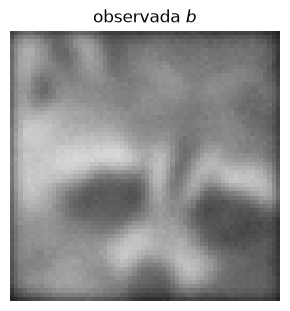

In [3]:
def mostrar(imagenes, titulos, archivo=None):
    """Muestra vectores de largo n como imágenes de N x N, lado a lado (valores fuera de [0, 1] se recortan)."""
    fig, axs = plt.subplots(1, len(imagenes), figsize=(3 * len(imagenes), 3.2))
    axs = np.atleast_1d(axs)
    for ax, v, t in zip(axs, imagenes, titulos):
        ax.imshow(v.reshape(N, N), cmap="gray", vmin=0, vmax=1)
        ax.set_title(t)
        ax.axis("off")
    fig.tight_layout()
    if archivo is not None:
        fig.savefig(os.path.join(FIGURAS, archivo), dpi=200, bbox_inches="tight")
    plt.show()


mostrar([b], ["observada $b$"], archivo="ejemplo_b.png")

## (a) Mínimos cuadrados

# Esta en el PDF correspondiente

## (b) Reconstrucción

### i. Implementación

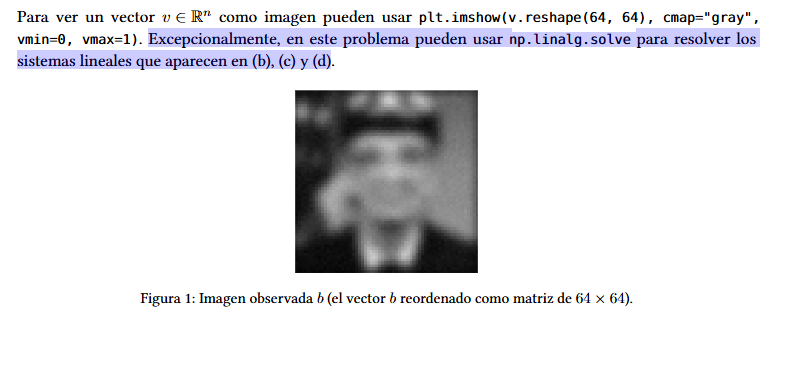

x0 =  [   22.40087356  1791.86906755 -4831.05959824 ...  4686.13426256
 -4895.73121023  2099.22454821]
b =  [0.2548257  0.31004885 0.36797129 ... 0.23360778 0.212878   0.14626747]
Norma ||x0||_2: 350302.18
Máximo absoluto max_i |x0_i|: 1.87e+04
Residuo ||A x0 - b||_2: 6.71e-12


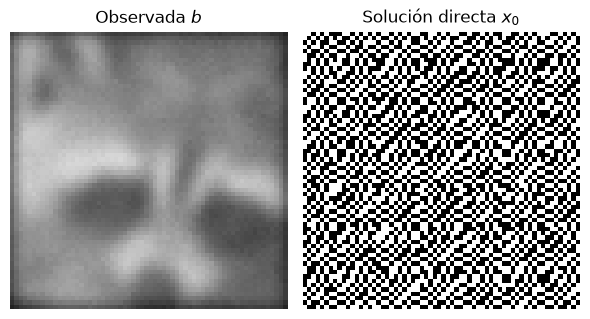

In [4]:
# TODO
# - Calcular x0 resolviendo Ax = b.
# - Reportar ||x0||_2, max_i |x0_i| y el residuo ||A x0 - b||_2.
# - Mostrar b y x0 lado a lado: mostrar([...], [...], archivo="P1_b_reconstruccion.png")


A = datos["A"]          
b = datos["b"]          
x0 = np.linalg.solve(A,b) 
print("x0 = ",x0)
print("b = ",b)

norma_x0 = np.linalg.norm(x0)
max_abs_x0 = np.max(np.abs(x0))
residuo_x0 = np.linalg.norm(A @ x0 - b)

print(f"Norma ||x0||_2: {norma_x0:.2f}")
print(f"Máximo absoluto max_i |x0_i|: {max_abs_x0:.2e}")
print(f"Residuo ||A x0 - b||_2: {residuo_x0:.2e}")

mostrar(
    imagenes=[b, x0], 
    titulos=["Observada $b$", "Solución directa $x_0$"], 
    archivo="P1_b_reconstruccion.png"
)


### ii. Explicación

## (c) Regularización de Tikhonov

### iv. Implementación

delta = 0.64

reconstrucción             ||x||_2    max|x_i|    ||Ax-b||_2  residuo/delta
x0                       3.503e+05   1.871e+04     6.712e-12      1.049e-11
lambda = 10^{-3.5}           37.06       1.178        0.5617         0.8776
lambda = 10^{-2.5}           36.02      0.9618        0.6169          0.964
lambda = 1                   17.18      0.4171         17.85           27.9


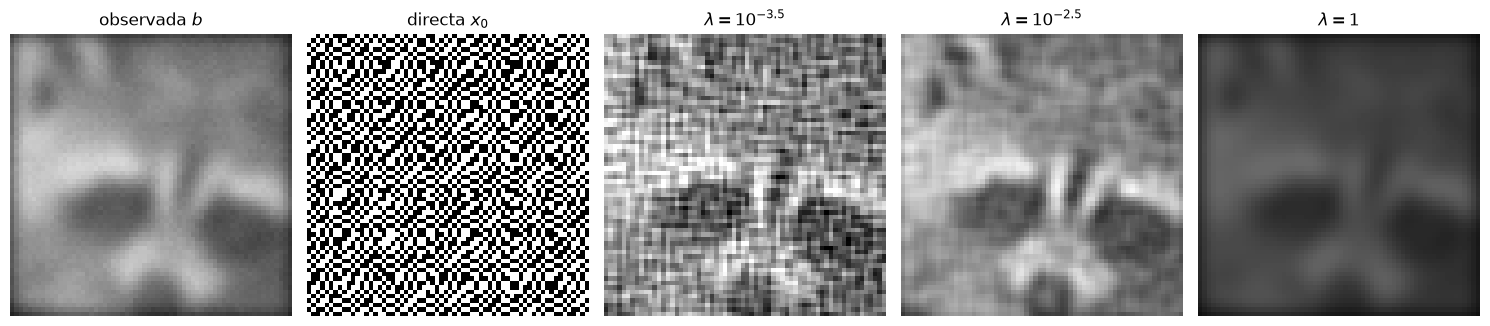

In [5]:
# Calcular A^T A una sola vez, porque es la operación más costosa y se reutiliza en (d)
AtA = A.T @ A
I = np.eye(n)


def tikhonov(observacion, lam):
    """Resuelve (A^T A + lam I) x = A^T observacion."""
    return np.linalg.solve(AtA + lam * I, A.T @ observacion)


lambdas = [10**-3.5, 10**-2.5, 1.0]
nombres = ["10^{-3.5}", "10^{-2.5}", "1"]
x_lam = [tikhonov(b, lam) for lam in lambdas]

print(f"delta = {delta:.2f}\n")
print(f"{'reconstrucción':<22}{'||x||_2':>12}{'max|x_i|':>12}{'||Ax-b||_2':>14}{'residuo/delta':>15}")
for nombre, x in zip(["x0"] + [f"lambda = {m}" for m in nombres], [x0] + x_lam):
    residuo = np.linalg.norm(A @ x - b)
    print(f"{nombre:<22}{np.linalg.norm(x):>12.4g}{np.max(np.abs(x)):>12.4g}{residuo:>14.4g}{residuo / delta:>15.4g}")

mostrar(
    [b, x0] + x_lam,
    ["observada $b$", "directa $x_0$"] + [rf"$\lambda = {m}$" for m in nombres],
    archivo="P1_c_tikhonov.png",
)

## (d) Píxeles dañados

||x_def||_2 = 45.91
max|x_def_i| = 2.395
||A x_def - b_def||_2 = 10


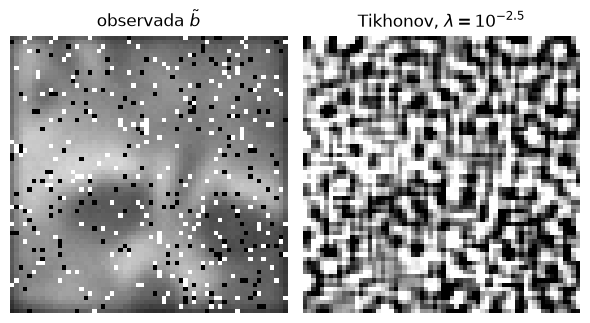

In [6]:
lam_d = 10**-2.5
x_def = tikhonov(b_def, lam_d)

print(f"||x_def||_2 = {np.linalg.norm(x_def):.4g}")
print(f"max|x_def_i| = {np.max(np.abs(x_def)):.4g}")
print(f"||A x_def - b_def||_2 = {np.linalg.norm(A @ x_def - b_def):.4g}")

mostrar(
    [b_def, x_def],
    [r"observada $\tilde{b}$", r"Tikhonov, $\lambda = 10^{-2.5}$"],
    archivo="P1_d_danados.png",
)

### ii. $\|\tilde{b} - b\|_2$

In [7]:
danados = (b_def == 0) | (b_def == 1)
dif = b_def - b
norma_dif = np.linalg.norm(dif)

print(f"píxeles dañados: {danados.sum()} de {n} ({100 * danados.mean():.1f} %)")
print(f"||b_def - b||_2 = {norma_dif:.4f}")
print(f"máximo de |b_def - b| fuera de los píxeles dañados: {np.max(np.abs(dif[~danados])):.1e}")
print(f"máximo de |b_def - b| en los píxeles dañados: {np.max(np.abs(dif[danados])):.4f}")

# eta no se conoce, así que ||eta_tilde|| se acota con la desigualdad triangular
cota_inf, cota_sup = norma_dif - delta, norma_dif + delta
print(f"\n{cota_inf:.2f} <= ||eta_tilde||_2 <= {cota_sup:.2f}")
print(f"||eta_tilde||_2 / delta está entre {cota_inf / delta:.1f} y {cota_sup / delta:.1f}")

píxeles dañados: 430 de 4096 (10.5 %)
||b_def - b||_2 = 10.7437
máximo de |b_def - b| fuera de los píxeles dañados: 0.0e+00
máximo de |b_def - b| en los píxeles dañados: 0.8225

10.10 <= ||eta_tilde||_2 <= 11.38
||eta_tilde||_2 / delta está entre 15.8 y 17.8


### iii. ¿Bastaría con aumentar $\lambda$?

Con lambda = 10^-2.5:
  ruido original: delta / (2 sqrt(lambda)) = 5.69
  píxeles dañados: ||b_def - b|| / (2 sqrt(lambda)) = 95.53

lambda para recuperar la cota original: 0.891



lambda           ||x||_2   ||x - x_ref||_2   ||Ax - b_def||_2
10^{-2.5}          45.91              28.5                 10
10^{-1.5}          35.61             8.449              10.35
10^{-0.5}          26.61             10.46              13.73
1                  17.16              19.3              20.73


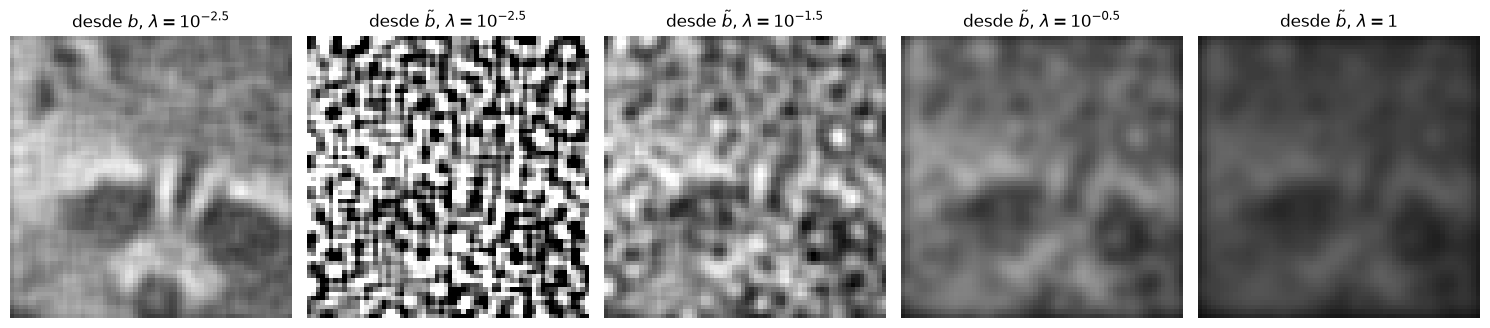

In [8]:
# Cota del aporte del ruido, ||ruido|| / (2 sqrt(lambda)), con cada ruido
print(f"Con lambda = 10^-2.5:")
print(f"  ruido original: delta / (2 sqrt(lambda)) = {delta / (2 * np.sqrt(lam_d)):.2f}")
print(f"  píxeles dañados: ||b_def - b|| / (2 sqrt(lambda)) = {norma_dif / (2 * np.sqrt(lam_d)):.2f}")

# lambda necesario para que la cota con los píxeles dañados vuelva al valor original
lam_equivalente = lam_d * (norma_dif / delta) ** 2
print(f"\nlambda para recuperar la cota original: {lam_equivalente:.3f}")

# Aumentar lambda: se compara cada reconstrucción con la obtenida desde b (sin píxeles dañados, lambda = 10^-2.5)
referencia = x_lam[1]
lambdas_d = [10**-2.5, 10**-1.5, 10**-0.5, 1.0]
nombres_d = ["10^{-2.5}", "10^{-1.5}", "10^{-0.5}", "1"]
x_def_lam = [tikhonov(b_def, lam) for lam in lambdas_d]

print(f"\n{'lambda':<14}{'||x||_2':>10}{'||x - x_ref||_2':>18}{'||Ax - b_def||_2':>19}")
for m, x in zip(nombres_d, x_def_lam):
    print(f"{m:<14}{np.linalg.norm(x):>10.4g}{np.linalg.norm(x - referencia):>18.4g}{np.linalg.norm(A @ x - b_def):>19.4g}")

mostrar(
    [referencia] + x_def_lam,
    [r"desde $b$, $\lambda = 10^{-2.5}$"] + [rf"desde $\tilde{{b}}$, $\lambda = {m}$" for m in nombres_d],
    archivo="P1_d_lambda.png",
)

## (Bonus) Mínimos cuadrados ponderados

In [9]:
# TODO
# - Implementar la reconstrucción que minimiza J_W, con W = diag(w) y w_p = 0 si el píxel p está dañado.
# - Mostrar el resultado: archivo="P1_bonus_ponderados.png"